<a href="https://colab.research.google.com/github/Ananya9-tech/AI101-Mini-Project/blob/main/ai101miniproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape (4500, 16)
Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Primary_Platform',
       'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Device_Type',
       'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Late_Night_Usage',
       'Social_Comparison_Frequency', 'Perceived_Stress_Score',
       'Mental_Health_Index', 'Academic_Performance_GPA', 'Overall_Impact'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   object 
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   object 
 3   Academic_Level               4500 non-null   object 
 4   Primary_Platform             4500 non-null   object 
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours         

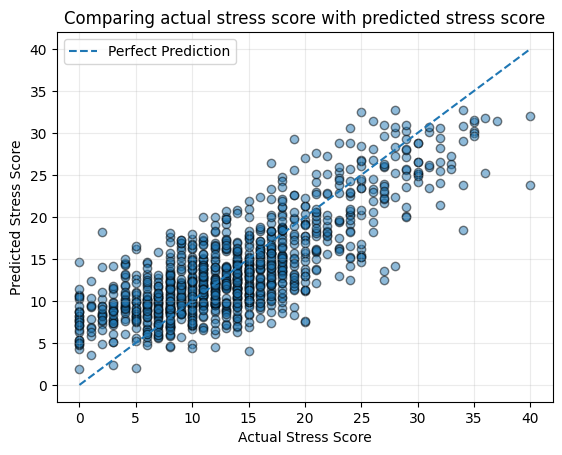

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df=pd.read_csv("Social_media_impact_on_life.csv")
#Checking the dataset
print("Shape",df.shape)
print(df.columns)
print(df.info())
print(df.describe())
#Setting the input features and target variable
features=["Daily_Usage_Hours","Weekend_Extra_Hours","Sleep_Duration_Hours","Sleep_Quality_Score"]
target="Perceived_Stress_Score"
#Validate column names
missing_columns=[
    col for col in features+[target]
                 if col not in df.columns
    ]
if missing_columns:
  print("Error:These columns do not exist",missing_columns)
else:
  print("Target",target)
  print("Features",features)

#Keep only selected features and target
model_df=df[features+[target]].copy()
#Convert the target to numeric
model_df[target]=pd.to_numeric(model_df[target],errors="coerce")
model_df.head()
#Checking for missing values of target
print("Missing target values",model_df[target].isnull().sum())
#Remove the rows where target is missing
model_df=model_df.dropna(subset=[target])
#Checking for missing values in features
print(model_df[features].isnull().sum())

X=model_df[features]
Y=model_df[target]

#Detect numeric and categorical input features
numeric_features=X.select_dtypes(include=np.number).columns.tolist()
categorical_features=X.select_dtypes(exclude=np.number).columns.tolist()
print("Numeric features",numeric_features)
print("Categorical features",categorical_features)

#Understanding data through mean,median,standard deviation,covariance,correlation
print("Mean",model_df[features+[target]].mean())
print("Median",model_df[features+[target]].median())
print("Standard deviation",model_df[features+[target]].std())
print("Covariance",model_df[features+[target]].cov())
print("Correlation",model_df[features+[target]].corr())


#Split into train and test data
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.25,random_state=30)
print("Total samples",len(X))
print("Training sample",len(X_train))
print("Testing set",len(X_test))

#Create the model pipeline and train it
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,Y_train)

#Predict target for training data
Y_pred_train=model.predict(X_train)


#Predict target for test data
Y_pred=model.predict(X_test)
comparison=pd.DataFrame({
    "Actual Stress Score":Y_test.to_numpy(),
    "Predicted Stress Score": Y_pred,
    "Error":Y_test.to_numpy()-Y_pred
})
comparison.head(10)

#Evaluate the model on train data
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
print("Training MAE",mean_absolute_error(Y_train,Y_pred_train))
print("Training MSE",mean_squared_error(Y_train,Y_pred_train))
print("Training RMSE",np.sqrt(mean_squared_error(Y_train,Y_pred_train)))
print("Training R2 Score",r2_score(Y_train,Y_pred_train))


#Evaluate the model on test data
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
print("Testing MAE",mean_absolute_error(Y_test,Y_pred))
print("Testing MSE",mean_squared_error(Y_test,Y_pred))
print("Testing RMSE",np.sqrt(mean_squared_error(Y_test,Y_pred)))
print("Testing R2 Score",r2_score(Y_test,Y_pred))

#Training details with plots
plt.scatter(Y_test,Y_pred,alpha=0.5,edgecolor="black")
#Reference Line
low=min(np.min(Y_test),np.min(Y_pred))
high=max(np.max(Y_test),np.max(Y_pred))
plt.plot([low,high],[low,high],linestyle="--",label="Perfect Prediction")

plt.xlabel("Actual Stress Score")
plt.ylabel("Predicted Stress Score")
plt.title("Comparing actual stress score with predicted stress score")
plt.legend()
plt.grid(alpha=0.25)
plt.show()





















